# Order Cab

In [8]:
from lakehouse import LakeConfig, connect

lake = LakeConfig.from_env()
con = connect()   # DuckDB already authenticated on MinIO (minio:9000)

order_cab = lake.uri("bronze", "mysql", "order_cab") + "/*/*.parquet"

df_resultado = con.sql(f"""
    SELECT DISTINCT MARK_COD
    FROM read_parquet('{order_cab}', filename = true, hive_partitioning = true)
""").df()
df_resultado

,MARK_COD
0,Zalando PL
1,Online PL
2,Online HU
3,Online PE
4,Online ES
5,TRENDYOL TR
6,Online BE
7,Online NL
8,Online LT
9,Online SE


In [9]:
from lakehouse import LakeConfig, connect

lake = LakeConfig.from_env()
con = connect()   # DuckDB already authenticated on MinIO (minio:9000)

order_cab = lake.uri("bronze", "mysql", "order_cab") + "/*/*.parquet"

df_resultado = con.sql(f"""
    SELECT DISTINCT ORDER_ORIGIN
    FROM read_parquet('{order_cab}', filename = true, hive_partitioning = true)
""").df()
df_resultado

,ORDER_ORIGIN
0,ZALANDO
1,PARFOIS Franchise
2,PARFOIS
3,ECI


In [ ]:

from lakehouse import LakeConfig, connect

lake = LakeConfig.from_env()
con = connect()   # DuckDB already authenticated on MinIO (minio:9000)

order_cab = lake.uri("bronze", "mysql", "order_cab") + "/*/*.parquet"

df_resultado = con.sql(f"""
    SELECT *
    FROM read_parquet('{order_cab}', filename = true, hive_partitioning = true)
    WHERE ORDER_CHANEL_TYPE IN ('DESKTOP', 'APP');
""").df()
df_resultado



FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [1]:
from lakehouse import LakeConfig, connect

lake = LakeConfig.from_env()
con = connect()   # DuckDB already authenticated on MinIO (minio:9000)

order_cab = lake.uri("bronze", "mysql", "order_cab") + "/*/*.parquet"

df_resultado = con.sql(f"""
    SELECT 
    DATE(ORDER_DATE) AS data_ordem, 
    ORDER_CHANEL_TYPE, 
    COUNT(ORDER_ID) AS total_ordens
    FROM read_parquet('{order_cab}', filename = true, hive_partitioning = true)
    GROUP BY DATE(ORDER_DATE), ORDER_CHANEL_TYPE
    ORDER BY data_ordem;
""").df()
df_resultado


,data_ordem,ORDER_CHANEL_TYPE,total_ordens
0,2020-03-10,DESKTOP,1
1,2021-08-23,DESKTOP,1
2,2021-11-26,DESKTOP,1
3,2022-01-12,DESKTOP,1
4,2022-01-14,APP,1
...,...,...,...
3287,2025-12-30,DESKTOP,9864
3288,2025-12-31,STORE,407
3289,2025-12-31,APP,1372
3290,2025-12-31,ND,1181


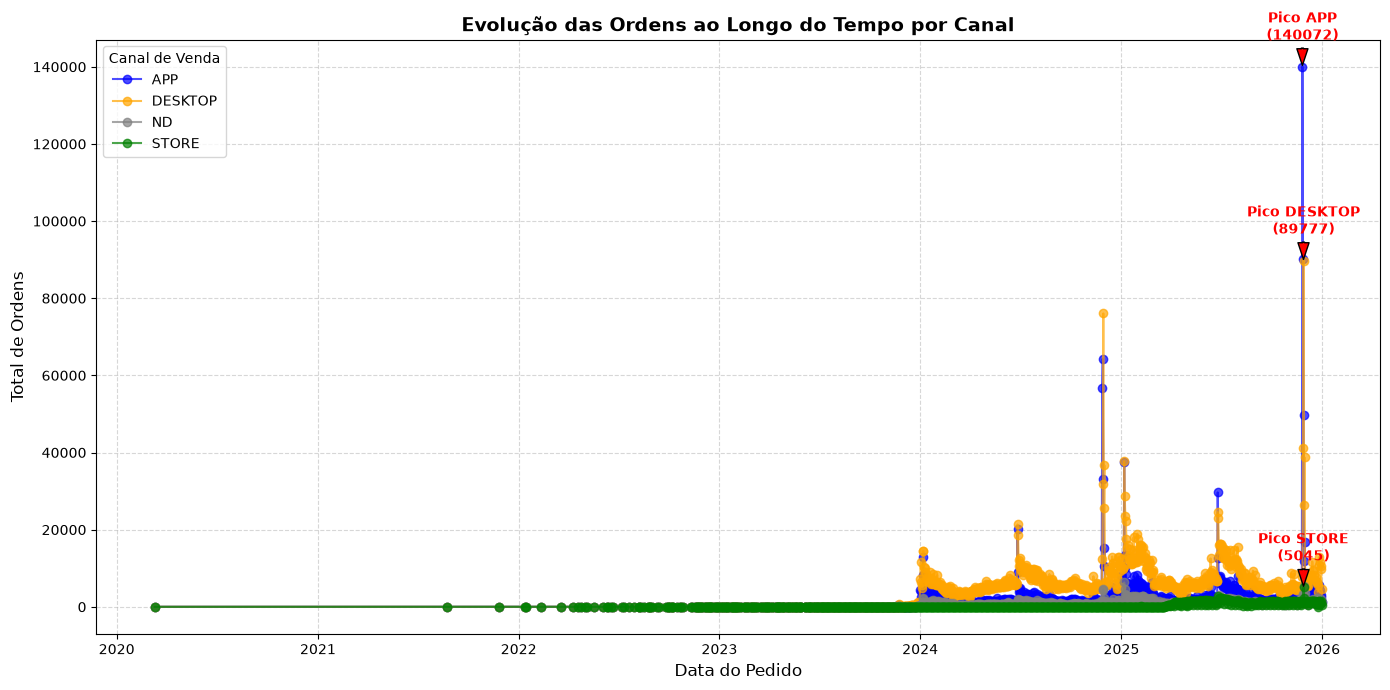

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Garante que a coluna de data esteja no formato datetime
df_resultado['data_ordem'] = pd.to_datetime(df_resultado['data_ordem'])

# Pivota o DataFrame para colocar as datas no índice e os canais nas colunas
df_pivot = df_resultado.pivot(index='data_ordem', columns='ORDER_CHANEL_TYPE', values='total_ordens').fillna(0)

# Inicializa a figura
plt.figure(figsize=(14, 7))

# Define cores para os canais conhecidos
cores = {'APP': 'blue', 'DESKTOP': 'orange', 'STORE': 'green', 'ND': 'gray'}

# Plota a linha de cada canal
for canal in df_pivot.columns:
    plt.plot(df_pivot.index, df_pivot[canal], marker='o', label=canal, color=cores.get(canal, 'black'), alpha=0.7)

# Destaca os 3 pontos: Picos de ordens para APP, DESKTOP e STORE
canais_destaque = ['APP', 'DESKTOP', 'STORE']
deslocamento_y = df_pivot.values.max() * 0.05 # Deslocamento proporcional para a anotação

for canal in canais_destaque:
    if canal in df_pivot.columns and df_pivot[canal].max() > 0:
        data_pico = df_pivot[canal].idxmax()
        valor_pico = df_pivot[canal].max()
        
        plt.annotate(
            f'Pico {canal}\n({int(valor_pico)})',
            xy=(data_pico, valor_pico),
            xytext=(data_pico, valor_pico + deslocamento_y),
            arrowprops=dict(facecolor='red', shrink=0.05, width=1.5, headwidth=8),
            fontsize=10,
            fontweight='bold',
            color='red',
            ha='center'
        )

# Configurações de layout do gráfico
plt.title('Evolução das Ordens ao Longo do Tempo por Canal', fontsize=14, fontweight='bold')
plt.xlabel('Data do Pedido', fontsize=12)
plt.ylabel('Total de Ordens', fontsize=12)
plt.legend(title='Canal de Venda')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# Exibe o gráfico
plt.show()

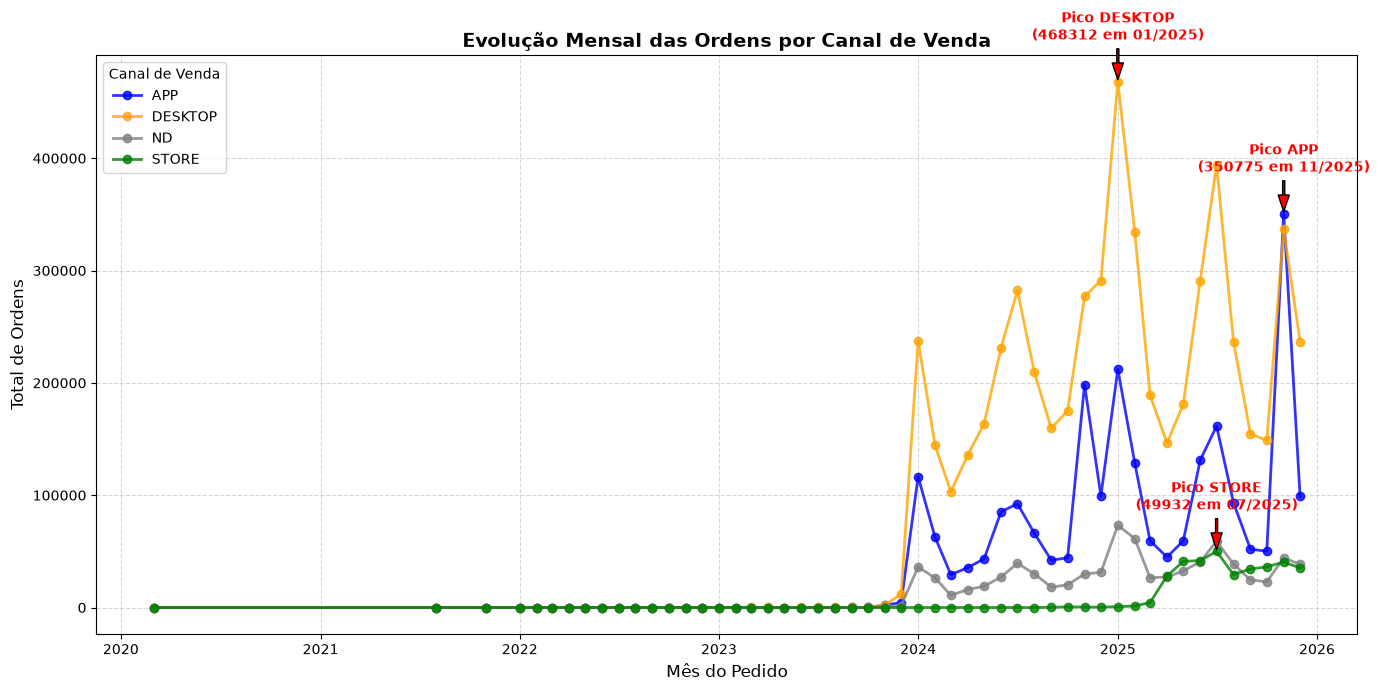

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Converte a coluna para datetime e extrai o período mensal
df_resultado['data_ordem'] = pd.to_datetime(df_resultado['data_ordem'])
df_resultado['mes_ano'] = df_resultado['data_ordem'].dt.to_period('M')

# 2. Agrupa somando as ordens por mês e canal
df_mensal = df_resultado.groupby(['mes_ano', 'ORDER_CHANEL_TYPE'])['total_ordens'].sum().reset_index()

# 3. Converte o período de volta para timestamp (o Matplotlib lida melhor com datas assim no eixo X)
df_mensal['mes_ano'] = df_mensal['mes_ano'].dt.to_timestamp()

# 4. Pivota os dados com os meses no índice
df_pivot = df_mensal.pivot(index='mes_ano', columns='ORDER_CHANEL_TYPE', values='total_ordens').fillna(0)

# 5. Inicializa a figura
plt.figure(figsize=(14, 7))
cores = {'APP': 'blue', 'DESKTOP': 'orange', 'STORE': 'green', 'ND': 'gray'}

# 6. Plota a linha de cada canal
for canal in df_pivot.columns:
    plt.plot(df_pivot.index, df_pivot[canal], marker='o', linewidth=2, label=canal, color=cores.get(canal, 'black'), alpha=0.8)

# 7. Destaca os 3 pontos: Picos de ordens mensais para APP, DESKTOP e STORE
canais_destaque = ['APP', 'DESKTOP', 'STORE']
deslocamento_y = df_pivot.values.max() * 0.08 

for canal in canais_destaque:
    if canal in df_pivot.columns and df_pivot[canal].max() > 0:
        data_pico = df_pivot[canal].idxmax()
        valor_pico = df_pivot[canal].max()
        mes_str = data_pico.strftime('%m/%Y')
        
        plt.annotate(
            f'Pico {canal}\n({int(valor_pico)} em {mes_str})',
            xy=(data_pico, valor_pico),
            xytext=(data_pico, valor_pico + deslocamento_y),
            arrowprops=dict(facecolor='red', shrink=0.05, width=1.5, headwidth=8),
            fontsize=10,
            fontweight='bold',
            color='red',
            ha='center'
        )

# 8. Configurações de layout do gráfico
plt.title('Evolução Mensal das Ordens por Canal de Venda', fontsize=14, fontweight='bold')
plt.xlabel('Mês do Pedido', fontsize=12)
plt.ylabel('Total de Ordens', fontsize=12)
plt.legend(title='Canal de Venda')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# Exibe o gráfico
plt.show()

In [ ]:
from lakehouse import LakeConfig, connect

lake = LakeConfig.from_env()
con = connect()   # DuckDB already authenticated on MinIO (minio:9000)

order_cab = lake.uri("bronze", "mysql", "order_cab") + "/*/*.parquet"

df_resultado = con.sql(f"""
    SELECT *
    FROM read_parquet('{order_cab}', filename = true, hive_partitioning = true)
""").df()
df_resultado

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [1]:
from lakehouse import LakeConfig, connect

lake = LakeConfig.from_env()
con = connect()   # DuckDB already authenticated on MinIO (minio:9000)

events = lake.uri("bronze", "mysql", "events") + "/*/*.parquet"

df_resultado = con.sql(f"""
    SELECT *
    FROM read_parquet('{events}', filename = true, hive_partitioning = true)
""").df()
df_resultado

,MARK_COD,MARK_DES,EVENT,START_DATE,END_DATE,_ingested_at,_source_system,_source_entity,_batch_id,_load_id,filename,ingestion_date
0,Online PT,parfois.com,Clearance,2024-01-01,2024-02-28,2026-10-17 20:49:36,mysql,parfois.events,scheduled__2026-10-13T05_00_00_00_00,20261017T204936,s3://bronze/mysql/events/ingestion_date=2026-1...,2026-10-13
1,Online BE,parfois.com,Clearance,2024-01-02,2024-02-28,2026-10-17 20:49:36,mysql,parfois.events,scheduled__2026-10-13T05_00_00_00_00,20261017T204936,s3://bronze/mysql/events/ingestion_date=2026-1...,2026-10-13
2,Online IT,parfois.com,Clearance,2024-01-04,2024-02-28,2026-10-17 20:49:36,mysql,parfois.events,scheduled__2026-10-13T05_00_00_00_00,20261017T204936,s3://bronze/mysql/events/ingestion_date=2026-1...,2026-10-13
3,Online ES,parfois.com,Get your basket ready,2024-01-05,2024-01-05,2026-10-17 20:49:36,mysql,parfois.events,scheduled__2026-10-13T05_00_00_00_00,20261017T204936,s3://bronze/mysql/events/ingestion_date=2026-1...,2026-10-13
4,Online ES,parfois.com,Clearance,2024-01-06,2024-02-28,2026-10-17 20:49:36,mysql,parfois.events,scheduled__2026-10-13T05_00_00_00_00,20261017T204936,s3://bronze/mysql/events/ingestion_date=2026-1...,2026-10-13
...,...,...,...,...,...,...,...,...,...,...,...,...
805,Online PT,parfois.com,Free Shipping,2025-12-27,2025-12-28,2026-10-17 20:49:36,mysql,parfois.events,scheduled__2026-10-13T05_00_00_00_00,20261017T204936,s3://bronze/mysql/events/ingestion_date=2026-1...,2026-10-13
806,Online IT,parfois.com,Free Shipping,2025-12-27,2025-12-28,2026-10-17 20:49:36,mysql,parfois.events,scheduled__2026-10-13T05_00_00_00_00,20261017T204936,s3://bronze/mysql/events/ingestion_date=2026-1...,2026-10-13
807,Online ES,parfois.com,Last Days Reyes,2025-12-27,2025-12-30,2026-10-17 20:49:36,mysql,parfois.events,scheduled__2026-10-13T05_00_00_00_00,20261017T204936,s3://bronze/mysql/events/ingestion_date=2026-1...,2026-10-13
808,Online ES,parfois.com,Last Hours Reyes,2025-12-29,2025-12-30,2026-10-17 20:49:36,mysql,parfois.events,scheduled__2026-10-13T05_00_00_00_00,20261017T204936,s3://bronze/mysql/events/ingestion_date=2026-1...,2026-10-13
